# EDA — Dados do TSE (2022 e 2024)

Análise exploratória dos 5 datasets baixados do Portal de Dados Abertos do TSE
(`scripts/ingest_tse.py`), lidos a partir do parquet em `data/processed/`.
Objetivo: entender distribuições, anomalias e qualidade dos dados **antes**
de montar features pra um modelo de previsão de eleição de candidatos.

Datasets: `consulta_cand`, `bem_candidato`, `votacao_candidato_munzona`,
`prestacao_de_contas_eleitorais_candidatos` (receitas), `perfil_eleitorado`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)
pd.set_option("display.max_columns", 60)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
YEARS = [2022, 2024]

def load(dataset: str, year: int, columns=None) -> pd.DataFrame:
    matches = list((PROCESSED / dataset / str(year)).glob("*.parquet"))
    if not matches:
        raise FileNotFoundError(f"nenhum parquet em {PROCESSED / dataset / str(year)}")
    df = pd.read_parquet(matches[0], columns=columns)
    df["ANO_ELEICAO"] = year
    return df

def to_number(series: pd.Series) -> pd.Series:
    """Campos de valor do TSE vem como texto com virgula decimal."""
    return pd.to_numeric(series.astype(str).str.replace(",", ".", regex=False), errors="coerce")


## 1. Visão geral — tamanho e estrutura de cada dataset

In [2]:
DATASET_NAMES = [
    "consulta_cand",
    "bem_candidato",
    "votacao_candidato_munzona",
    "prestacao_de_contas_eleitorais_candidatos",
    "perfil_eleitorado",
]

overview = []
for ds in DATASET_NAMES:
    for year in YEARS:
        matches = list((PROCESSED / ds / str(year)).glob("*.parquet"))
        if not matches:
            continue
        df = pd.read_parquet(matches[0])
        overview.append({
            "dataset": ds,
            "ano": year,
            "linhas": len(df),
            "colunas": df.shape[1],
            "memoria_MB": round(df.memory_usage(deep=True).sum() / 1e6, 1),
        })
        del df

overview_df = pd.DataFrame(overview)
overview_df


,dataset,ano,linhas,colunas,memoria_MB
0,consulta_cand,2022,29322,50,24.3
1,consulta_cand,2024,463855,50,379.2
2,bem_candidato,2022,92559,19,34.0
3,bem_candidato,2024,911076,19,326.6
4,votacao_candidato_munzona,2022,9377845,50,7120.8
5,votacao_candidato_munzona,2024,717195,50,543.4
6,prestacao_de_contas_eleitorais_candidatos,2022,674944,60,661.8
7,prestacao_de_contas_eleitorais_candidatos,2024,2041000,60,2106.9
8,perfil_eleitorado,2022,4362480,27,1676.3
9,perfil_eleitorado,2024,8940315,27,3261.6


## 2. Candidaturas (`consulta_cand`) — a variável alvo

`DS_SIT_TOT_TURNO` é a situação de totalização. Derivamos o alvo binário
`eleito` a partir dela e olhamos o balanceamento de classes — importante
porque eleição é, por natureza, um problema **desbalanceado** (poucos
vencedores por muitos candidatos).


In [3]:
CAND_COLS = [
    "SQ_CANDIDATO", "NR_CANDIDATO", "NM_CANDIDATO", "DS_CARGO", "SG_UF",
    "NR_PARTIDO", "SG_PARTIDO", "DS_GENERO", "DS_GRAU_INSTRUCAO",
    "DS_ESTADO_CIVIL", "DS_COR_RACA", "DS_OCUPACAO", "DT_NASCIMENTO",
    "DS_SIT_TOT_TURNO", "DS_SITUACAO_CANDIDATURA", "NR_CPF_CANDIDATO",
    "NR_TITULO_ELEITORAL_CANDIDATO", "NR_TURNO",
]

cand = pd.concat([load("consulta_cand", y, columns=CAND_COLS) for y in YEARS], ignore_index=True)
print(cand.shape)
cand.head(3)


(493177, 19)


,SQ_CANDIDATO,NR_CANDIDATO,NM_CANDIDATO,DS_CARGO,SG_UF,NR_PARTIDO,SG_PARTIDO,DS_GENERO,DS_GRAU_INSTRUCAO,DS_ESTADO_CIVIL,DS_COR_RACA,DS_OCUPACAO,DT_NASCIMENTO,DS_SIT_TOT_TURNO,DS_SITUACAO_CANDIDATURA,NR_CPF_CANDIDATO,NR_TITULO_ELEITORAL_CANDIDATO,NR_TURNO,ANO_ELEICAO
0,250001597749,30202,PRISCILA GONÇALVES IEIRI PARRA,DEPUTADO ESTADUAL,SP,30,NOVO,NÃO DIVULGÁVEL,NÃO DIVULGÁVEL,NÃO DIVULGÁVEL,NÃO DIVULGÁVEL,NÃO DIVULGÁVEL,NaN,SUPLENTE,APTO,-4,-4,1,2022
1,230002529897,22,VELTON QUINCOZES POLETO,VICE-GOVERNADOR,RR,22,PL,MASCULINO,SUPERIOR COMPLETO,CASADO(A),BRANCA,MILITAR REFORMADO,02/03/1977,NÃO ELEITO,APTO,90428846068,056241810400,1,2022
2,120001648884,90033,MARY EMMILIM SANTOS DE ANDRADE,DEPUTADO ESTADUAL,MS,90,PROS,NÃO DIVULGÁVEL,NÃO DIVULGÁVEL,NÃO DIVULGÁVEL,NÃO DIVULGÁVEL,NÃO DIVULGÁVEL,NaN,#NULO,INAPTO,-4,-4,1,2022


DS_SIT_TOT_TURNO,#NULO,2º TURNO,ELEITO,ELEITO POR MÉDIA,ELEITO POR QP,NÃO ELEITO,SUPLENTE
ANO_ELEICAO,,,,,,,
2022,1662,52,137,390,1182,11221,14678
2024,16204,200,11130,17993,40159,141427,236742


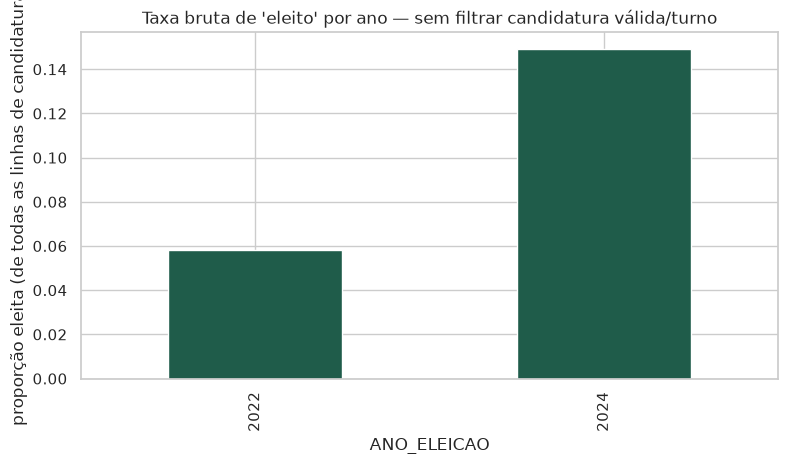

In [4]:
sit_counts = cand.groupby(["ANO_ELEICAO", "DS_SIT_TOT_TURNO"]).size().unstack(fill_value=0)
display(sit_counts)

ELEITO_LABELS = {"ELEITO", "ELEITO POR QP", "ELEITO POR MÉDIA"}
cand["eleito"] = cand["DS_SIT_TOT_TURNO"].isin(ELEITO_LABELS).astype(int)

fig, ax = plt.subplots()
cand.groupby("ANO_ELEICAO")["eleito"].mean().plot(kind="bar", ax=ax, color="#1f5c4a")
ax.set_ylabel("proporção eleita (de todas as linhas de candidatura)")
ax.set_title("Taxa bruta de 'eleito' por ano — sem filtrar candidatura válida/turno")
plt.show()


**Cuidado:** essa taxa bruta mistura candidaturas indeferidas/cassadas e o
2º turno (que só existe pra majoritário e reduz a base). Antes de treinar,
filtrar `DS_SITUACAO_CANDIDATURA` para candidaturas válidas e decidir se o
modelo trata 1º e 2º turno separadamente.


## 3. Perfil demográfico dos candidatos

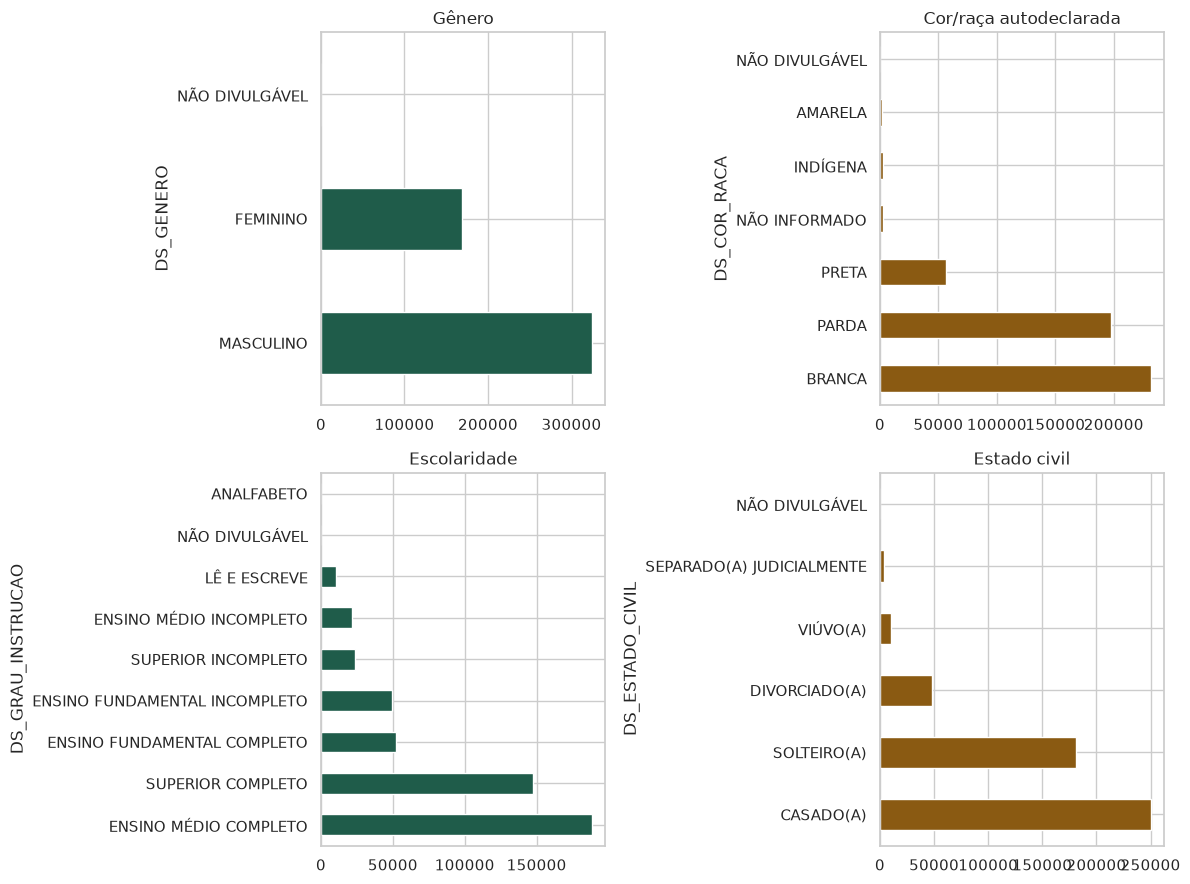

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

cand["DS_GENERO"].value_counts().plot(kind="barh", ax=axes[0, 0], color="#1f5c4a")
axes[0, 0].set_title("Gênero")

cand["DS_COR_RACA"].value_counts().plot(kind="barh", ax=axes[0, 1], color="#8a5a12")
axes[0, 1].set_title("Cor/raça autodeclarada")

cand["DS_GRAU_INSTRUCAO"].value_counts().plot(kind="barh", ax=axes[1, 0], color="#1f5c4a")
axes[1, 0].set_title("Escolaridade")

cand["DS_ESTADO_CIVIL"].value_counts().plot(kind="barh", ax=axes[1, 1], color="#8a5a12")
axes[1, 1].set_title("Estado civil")

plt.tight_layout()
plt.show()


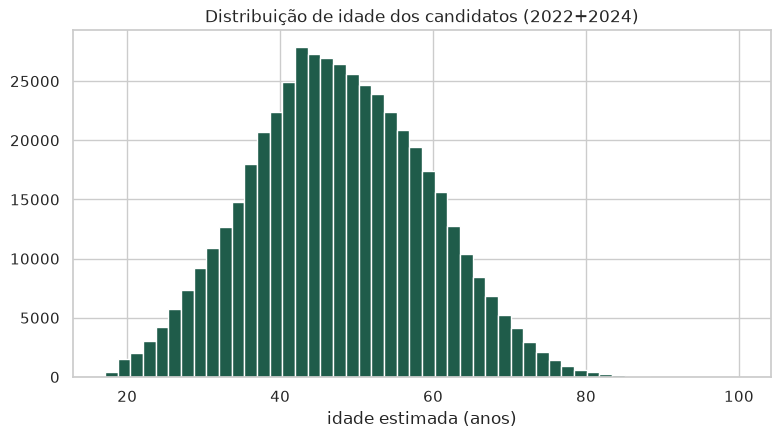

idade minima: 17.08145106091718  maxima: 1049.2320328542094  nulos: 75


In [6]:
nascimento = pd.to_datetime(cand["DT_NASCIMENTO"], format="%d/%m/%Y", errors="coerce")
idade = (pd.Timestamp("2024-10-01") - nascimento).dt.days / 365.25

fig, ax = plt.subplots()
idade.clip(upper=100).hist(bins=50, ax=ax, color="#1f5c4a", edgecolor="white")
ax.set_xlabel("idade estimada (anos)")
ax.set_title("Distribuição de idade dos candidatos (2022+2024)")
plt.show()

print("idade minima:", idade.min(), " maxima:", idade.max(), " nulos:", nascimento.isna().sum())


## 4. Anomalias e qualidade de dado em `consulta_cand`

In [7]:
print("NR_CPF_CANDIDATO — valores unicos:", cand['NR_CPF_CANDIDATO'].unique()[:5])
print("proporcao mascarada (-4):", (cand['NR_CPF_CANDIDATO'] == '-4').mean())

sentinelas = ["-1", "-3", "-4", "#NULO", "#NE"]
sentinel_share = (
    cand.drop(columns=["ANO_ELEICAO"])
    .apply(lambda s: s.astype(str).isin(sentinelas).mean())
    .sort_values(ascending=False)
)
sentinel_share[sentinel_share > 0]


NR_CPF_CANDIDATO — valores unicos: <ArrowStringArray>
['-4', '90428846068', '12629227391', '30752727877', '15008652818']
Length: 5, dtype: str
proporcao mascarada (-4): 0.9406034750201246


NR_CPF_CANDIDATO                 0.940603
DS_SITUACAO_CANDIDATURA          0.940545
DS_SIT_TOT_TURNO                 0.036226
NR_TITULO_ELEITORAL_CANDIDATO    0.000152
dtype: float64

In [8]:
dup_sq = cand.duplicated(subset=["SQ_CANDIDATO", "ANO_ELEICAO"]).sum()
print("SQ_CANDIDATO duplicado dentro do mesmo ano:", dup_sq)

titulos_2022 = set(cand.loc[cand.ANO_ELEICAO == 2022, "NR_TITULO_ELEITORAL_CANDIDATO"])
titulos_2024 = set(cand.loc[cand.ANO_ELEICAO == 2024, "NR_TITULO_ELEITORAL_CANDIDATO"])
reaparecem = titulos_2022 & titulos_2024
print(f"candidatos (por titulo eleitoral) que aparecem em 2022 E 2024: {len(reaparecem)} "
      f"de {len(titulos_2024)} candidatos de 2024 "
      f"({len(reaparecem) / len(titulos_2024):.1%})")


SQ_CANDIDATO duplicado dentro do mesmo ano: 256


candidatos (por titulo eleitoral) que aparecem em 2022 E 2024: 10016 de 462864 candidatos de 2024 (2.2%)


`NR_TITULO_ELEITORAL_CANDIDATO` funciona como chave estável de fato — dá pra
ver quem repetiu candidatura entre 2022 (geral) e 2024 (municipal), base
real para uma feature de "já foi candidato antes"/incumbência.


## 5. Bens de candidato — patrimônio declarado

In [9]:
bens = pd.concat(
    [load("bem_candidato", y, columns=["SQ_CANDIDATO", "DS_TIPO_BEM_CANDIDATO", "VR_BEM_CANDIDATO"]) for y in YEARS],
    ignore_index=True,
)
bens["valor"] = to_number(bens["VR_BEM_CANDIDATO"])
print(bens.shape)
bens["valor"].describe()


(1003635, 5)


count    1.003635e+06
mean     1.575495e+05
std      1.195565e+07
min      0.000000e+00
25%      8.686070e+03
50%      3.338775e+04
75%      1.000000e+05
max      1.060025e+10
Name: valor, dtype: float64

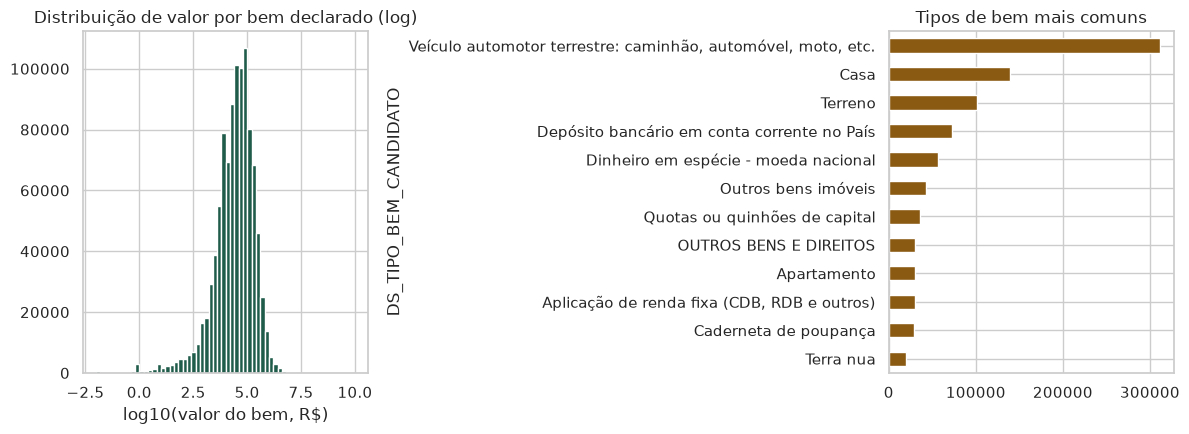

bens com valor <= 0: 2812 de 1003635
top 5 bens de maior valor:


,SQ_CANDIDATO,DS_TIPO_BEM_CANDIDATO,valor
230551,130002211844,Ações (inclusive as provenientes de linha tele...,1.060025e+10
300270,250001937618,Outras participações societárias,2.850000e+09
922884,140002233548,Outros bens imóveis,2.415000e+09
233654,210002201027,Quotas ou quinhões de capital,1.532580e+09
186625,270002288115,Terreno,1.500000e+09


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

np.log10(bens.loc[bens["valor"] > 0, "valor"]).hist(bins=60, ax=axes[0], color="#1f5c4a", edgecolor="white")
axes[0].set_xlabel("log10(valor do bem, R$)")
axes[0].set_title("Distribuição de valor por bem declarado (log)")

bens["DS_TIPO_BEM_CANDIDATO"].value_counts().head(12).plot(kind="barh", ax=axes[1], color="#8a5a12")
axes[1].set_title("Tipos de bem mais comuns")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print("bens com valor <= 0:", (bens['valor'] <= 0).sum(), "de", len(bens))
print("top 5 bens de maior valor:")
bens.nlargest(5, "valor")[["SQ_CANDIDATO", "DS_TIPO_BEM_CANDIDATO", "valor"]]


In [11]:
patrimonio = bens.groupby("SQ_CANDIDATO")["valor"].sum().rename("patrimonio_total")
patrimonio.describe()


count    3.143620e+05
mean     5.029940e+05
std      2.379584e+07
min      0.000000e+00
25%      3.000000e+04
50%      1.190000e+05
75%      3.242430e+05
max      1.210138e+10
Name: patrimonio_total, dtype: float64

## 6. Prestação de contas — receitas de campanha

In [12]:
receitas = pd.concat(
    [
        load(
            "prestacao_de_contas_eleitorais_candidatos", y,
            columns=["SQ_CANDIDATO", "DS_CARGO", "DS_ORIGEM_RECEITA", "DS_FONTE_RECEITA", "DS_ESPECIE_RECEITA", "VR_RECEITA"],
        )
        for y in YEARS
    ],
    ignore_index=True,
)
receitas["valor"] = to_number(receitas["VR_RECEITA"])
print(receitas.shape)
receitas["valor"].describe()


(2715944, 8)


count    2.715944e+06
mean     5.036332e+03
std      7.988151e+04
min      0.000000e+00
25%      5.000000e+01
50%      2.730000e+02
75%      1.200000e+03
max      6.670802e+07
Name: valor, dtype: float64

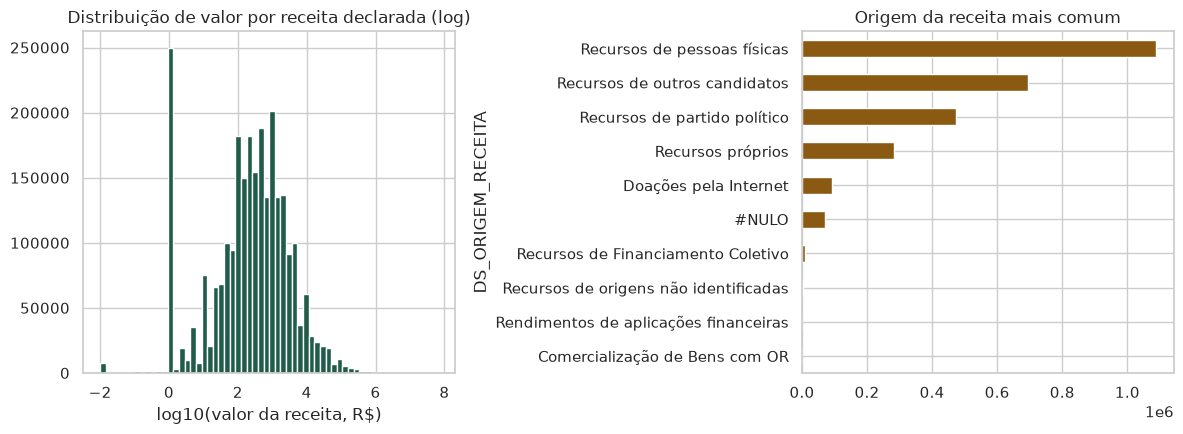

receitas com valor <= 0: 69581 de 2715944


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

np.log10(receitas.loc[receitas["valor"] > 0, "valor"]).hist(bins=60, ax=axes[0], color="#1f5c4a", edgecolor="white")
axes[0].set_xlabel("log10(valor da receita, R$)")
axes[0].set_title("Distribuição de valor por receita declarada (log)")

receitas["DS_ORIGEM_RECEITA"].value_counts().head(10).plot(kind="barh", ax=axes[1], color="#8a5a12")
axes[1].set_title("Origem da receita mais comum")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print("receitas com valor <= 0:", (receitas['valor'] <= 0).sum(), "de", len(receitas))


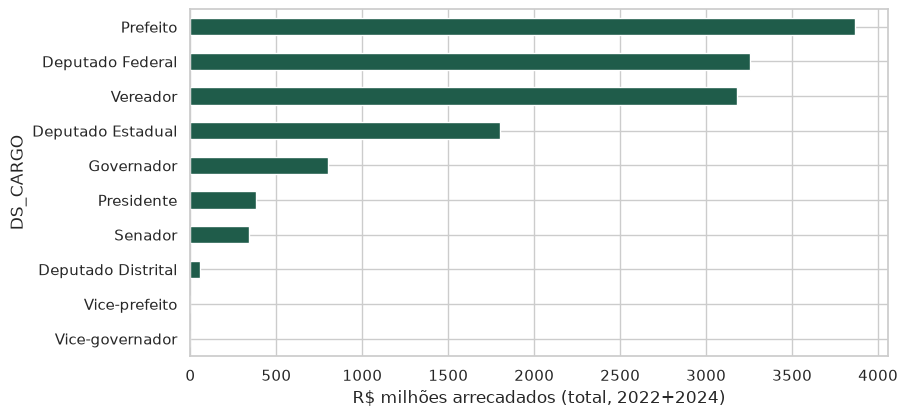

In [14]:
total_arrecadado = receitas.groupby("SQ_CANDIDATO")["valor"].sum().rename("total_arrecadado")
por_cargo = receitas.groupby("DS_CARGO")["valor"].sum().sort_values(ascending=False)

fig, ax = plt.subplots()
(por_cargo / 1e6).plot(kind="barh", ax=ax, color="#1f5c4a")
ax.set_xlabel("R$ milhões arrecadados (total, 2022+2024)")
ax.invert_yaxis()
plt.show()


## 7. Votação nominal

In [15]:
votos = pd.concat(
    [
        load("votacao_candidato_munzona", y, columns=["SQ_CANDIDATO", "DS_CARGO", "NR_TURNO", "QT_VOTOS_NOMINAIS", "DS_SIT_TOT_TURNO"])
        for y in YEARS
    ],
    ignore_index=True,
)
votos["QT_VOTOS_NOMINAIS"] = to_number(votos["QT_VOTOS_NOMINAIS"])
total_votos = votos.groupby(["SQ_CANDIDATO", "ANO_ELEICAO"])["QT_VOTOS_NOMINAIS"].sum().rename("total_votos").reset_index()
print(total_votos.shape)
total_votos["total_votos"].describe()


(454913, 3)


count    4.549130e+05
mean     2.105799e+03
std      2.461494e+05
min      0.000000e+00
25%      3.400000e+01
50%      1.070000e+02
75%      3.190000e+02
max      1.176055e+08
Name: total_votos, dtype: float64

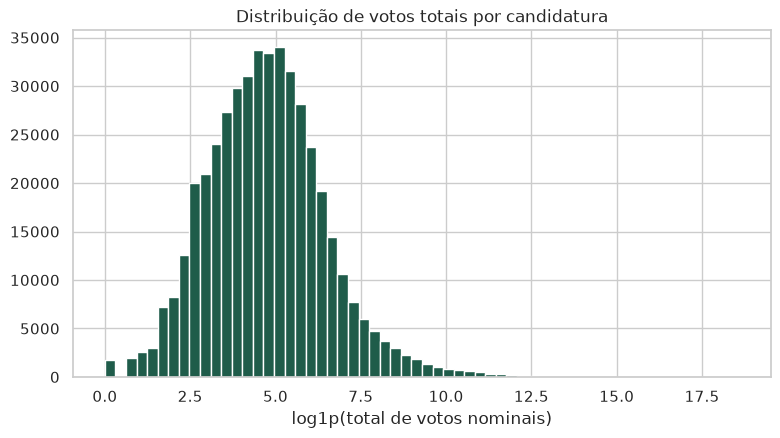

candidaturas com 0 votos: 0.4%


In [16]:
fig, ax = plt.subplots()
np.log1p(total_votos["total_votos"]).hist(bins=60, ax=ax, color="#1f5c4a", edgecolor="white")
ax.set_xlabel("log1p(total de votos nominais)")
ax.set_title("Distribuição de votos totais por candidatura")
plt.show()

zero_votos = (total_votos["total_votos"] == 0).mean()
print(f"candidaturas com 0 votos: {zero_votos:.1%}")


## 8. Perfil do eleitorado (contexto, não é por candidato)

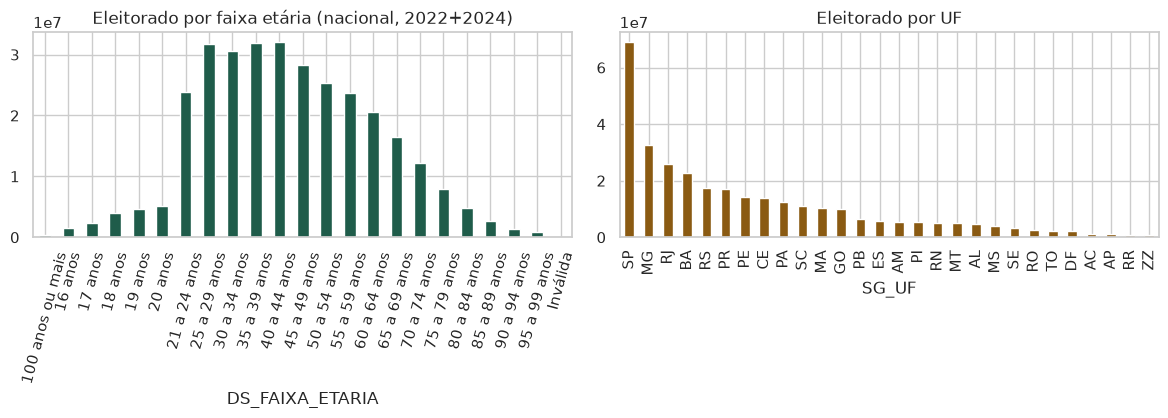

In [17]:
eleitorado = pd.concat(
    [load("perfil_eleitorado", y, columns=["SG_UF", "DS_FAIXA_ETARIA", "DS_GENERO", "DS_GRAU_ESCOLARIDADE", "QT_ELEITORES"]) for y in YEARS],
    ignore_index=True,
)
eleitorado["QT_ELEITORES"] = to_number(eleitorado["QT_ELEITORES"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

faixa = eleitorado.groupby("DS_FAIXA_ETARIA")["QT_ELEITORES"].sum().sort_index()
faixa.plot(kind="bar", ax=axes[0], color="#1f5c4a")
axes[0].set_title("Eleitorado por faixa etária (nacional, 2022+2024)")
axes[0].tick_params(axis="x", rotation=75)

por_uf = eleitorado.groupby("SG_UF")["QT_ELEITORES"].sum().sort_values(ascending=False)
por_uf.plot(kind="bar", ax=axes[1], color="#8a5a12")
axes[1].set_title("Eleitorado por UF")

plt.tight_layout()
plt.show()


## 9. Cruzando patrimônio e arrecadação com o resultado da eleição

Junta `consulta_cand` (alvo `eleito`) com o patrimônio total (seção 5) e a
receita total arrecadada (seção 6) por `SQ_CANDIDATO`. **Atenção**: isso
mistura o pleito de 2022 e o de 2024 sob a mesma chave `SQ_CANDIDATO`, que
não é comparável entre anos — é só uma checagem exploratória de correlação
dentro de cada linha, não uma feature de produção.


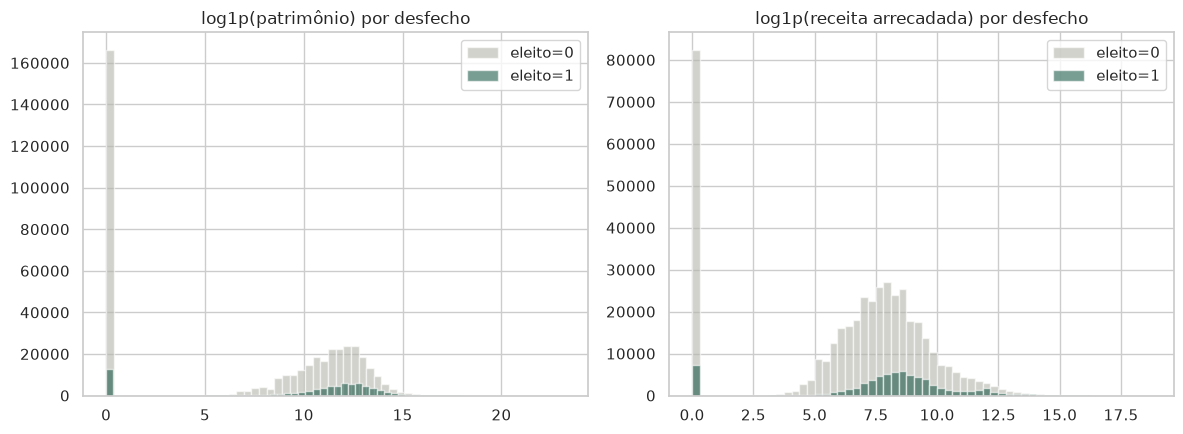

,patrimonio_total,total_arrecadado
eleito,,
0,15000.0,1617.5
1,120000.0,4472.5


In [18]:
painel = cand.merge(patrimonio, on="SQ_CANDIDATO", how="left").merge(total_arrecadado, on="SQ_CANDIDATO", how="left")
painel[["patrimonio_total", "total_arrecadado"]] = painel[["patrimonio_total", "total_arrecadado"]].fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for eleito, cor in [(0, "#b5b5ad"), (1, "#1f5c4a")]:
    subset = painel.loc[painel["eleito"] == eleito, "patrimonio_total"]
    np.log1p(subset).hist(bins=60, alpha=0.6, ax=axes[0], color=cor, label=f"eleito={eleito}")
axes[0].set_title("log1p(patrimônio) por desfecho")
axes[0].legend()

for eleito, cor in [(0, "#b5b5ad"), (1, "#1f5c4a")]:
    subset = painel.loc[painel["eleito"] == eleito, "total_arrecadado"]
    np.log1p(subset).hist(bins=60, alpha=0.6, ax=axes[1], color=cor, label=f"eleito={eleito}")
axes[1].set_title("log1p(receita arrecadada) por desfecho")
axes[1].legend()

plt.tight_layout()
plt.show()

painel.groupby("eleito")[["patrimonio_total", "total_arrecadado"]].median()


## 10. Resumo dos achados

**Escala dos dados** (2022 geral + 2024 municipal, consolidado nacional):
`votacao_candidato_munzona` de 2022 sozinho tem 9,4M linhas (~7 GB em pandas
com colunas como string) — se for treinar em cima disso, agregar por
candidato/UF cedo ou usar chunks/dask, não carregar tudo em memória de uma vez.

**Anomalias e cuidados confirmados nesta EDA:**

1. **`DS_SITUACAO_CANDIDATURA` não serve mais como filtro em 2024** — vem
   `#NE` (não existia registro naquele ano) para **100% das 463.855 linhas**.
   Em 2022 o mesmo campo tinha `APTO`/`INAPTO` normalmente. O dicionário
   recomendava filtrar por esse campo antes de treinar; isso não é mais
   possível para o pleito de 2024 — precisa achar outro critério de
   validade de candidatura (ex.: presença em `votacao_candidato_munzona`,
   ou uma situação diferente ainda não mapeada).
2. **`NR_CPF_CANDIDATO` mascarado por ano, não por sempre**: em 2022 só
   0,1% das linhas vêm `-4`; em 2024, **100%**. Confirma que a Resolução
   TSE nº 23.729/2024 começou a valer exatamente no pleito de 2024 — CPF
   é utilizável como identificador em anos anteriores, mas não em 2024+.
   `NR_TITULO_ELEITORAL_CANDIDATO` fica sendo a única chave estável.
3. **Reaparecimento entre pleitos é baixo e desigual**: só 2,2% dos
   candidatos de 2024 (10.016 de 462.864) têm o mesmo título eleitoral em
   2022 — esperado, já que 2022 é eleição geral (federal/estadual) e 2024
   é municipal, cargos diferentes. Uma feature de incumbência real
   precisa comparar o **mesmo cargo** entre o pleito atual e o *anterior
   do mesmo nível* (ex. municipal 2024 vs. municipal 2020), não anos
   consecutivos genéricos.
4. **Datas de nascimento com erro de digitação**: 4 registros com ano de
   nascimento tipo `0978`, `0993`, `0975`, `1793` — dígito de século
   sumiu ou erro de cadastro, gerando "idade" de centenas/milhares de
   anos. Poucos casos (4 em ~493 mil), mas quebram qualquer estatística
   de idade sem um clip/filtro antes (ex.: `idade.between(16, 100)`).
5. **Candidatos com idade abaixo do mínimo legal**: 8 registros com
   nascimento em 2006/2007, o que os deixaria com 17 anos ou menos na
   data da eleição — não dá pra confirmar se são candidaturas de fato
   indeferidas porque o campo de situação está `#NE` em 2024 (achado 1).
   Vale cruzar com `votacao_candidato_munzona` pra ver se essas
   candidaturas de fato chegaram a receber voto.
6. **256 `SQ_CANDIDATO` duplicados** dentro do mesmo ano — checar se são
   candidaturas com mais de uma linha por erro de exportação ou se
   representam algo válido (ex. duas coligações/situações registradas)
   antes de assumir 1 linha = 1 candidatura no pipeline de features.
7. **Cauda pesada em valores financeiros**, como esperado: bens
   declarados vão de R$ 0 até **R$ 10,6 bilhões** (uma única ação
   societária) e receita de campanha até R$ 66,7 milhões numa única
   doação — qualquer feature de patrimônio/arrecadação **precisa** de
   log-transform ou winsorização, média bruta não é uma estatística
   utilizável aqui.
8. **Correlação na direção esperada**: mediana de patrimônio é R$ 15 mil
   (não eleito) vs. R$ 120 mil (eleito); mediana de arrecadação é
   R$ 1.618 (não eleito) vs. R$ 4.473 (eleito). Confirma, nos dados reais,
   a hipótese do dicionário de que patrimônio e gasto de campanha
   carregam sinal preditivo — mas é uma comparação bruta sem controlar
   por cargo/UF, então serve só como indício, não como conclusão causal.

**Próximo passo natural**: resolver o achado nº 1 (critério de
candidatura válida em 2024) antes de montar o dataset de treino, porque
ele quebra o passo 1 da seção "Como montar o dataset" do dicionário.
